# 단일 모델 성능 개선

Adapter 전문가 없이 파생 피처 9~10개를 유지한 개선. 기존 벤치마크와 기존 모델은 보존.

## 1. 핵심 결과

- Isolation Forest: F1 33.62% → 38.56% (+4.93%p), Adapter 피처 9개, 목표 달성
- MiniBatch K-means: F1 33.71% → 42.56% (+8.85%p), Adapter 피처 9개, 목표 달성
- LOF: F1 39.19% → 42.66% (+3.47%p), Adapter 피처 9개, 목표 달성

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'reports/shared_model_improvement_refined/summary.json').exists())
OUT=ROOT/'reports/shared_model_improvement_refined'
read=lambda p: json.loads(p.read_text(encoding='utf-8'))
result=read(OUT/'summary.json'); old=read(ROOT/'reports/adapter_feature_ablation/summary.json'); selected=read(OUT/'selection.json')
def table(rows):
    df=pd.DataFrame(rows).set_index('method')
    return (df[[c for c in ['accuracy','precision','recall','f1','normal_false_positive_rate','average_precision','roc_auc'] if c in df]]*100).round(2)

## 2. 같은 전체 벤치마크에서 전후 비교

추가 전 / 첫 추가 실패 / 이번 개선. 단위 %. 오탐률은 낮을수록 좋다. Accuracy는 정상 비중에 영향을 받으므로 F1·Recall과 함께 본다.

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if_baseline,78.04,35.95,31.58,33.62,12.03,34.45,69.20
if_adapter_features,76.48,31.08,27.55,29.21,13.06,30.02,62.99
kmeans_baseline,79.43,38.98,29.70,33.71,9.94,32.77,65.89
kmeans_adapter_features,81.71,18.63,1.13,2.14,1.06,18.82,53.41
lof_baseline,81.98,48.33,32.96,39.19,7.53,45.87,73.45
lof_adapter_features,73.94,16.42,11.73,13.68,12.76,19.09,56.56
if_improved,78.24,38.37,38.75,38.56,13.31,38.26,72.42
kmeans_improved,79.91,42.87,42.26,42.56,12.04,37.84,71.77
lof_improved,83.29,53.91,35.30,42.66,6.45,46.43,73.00


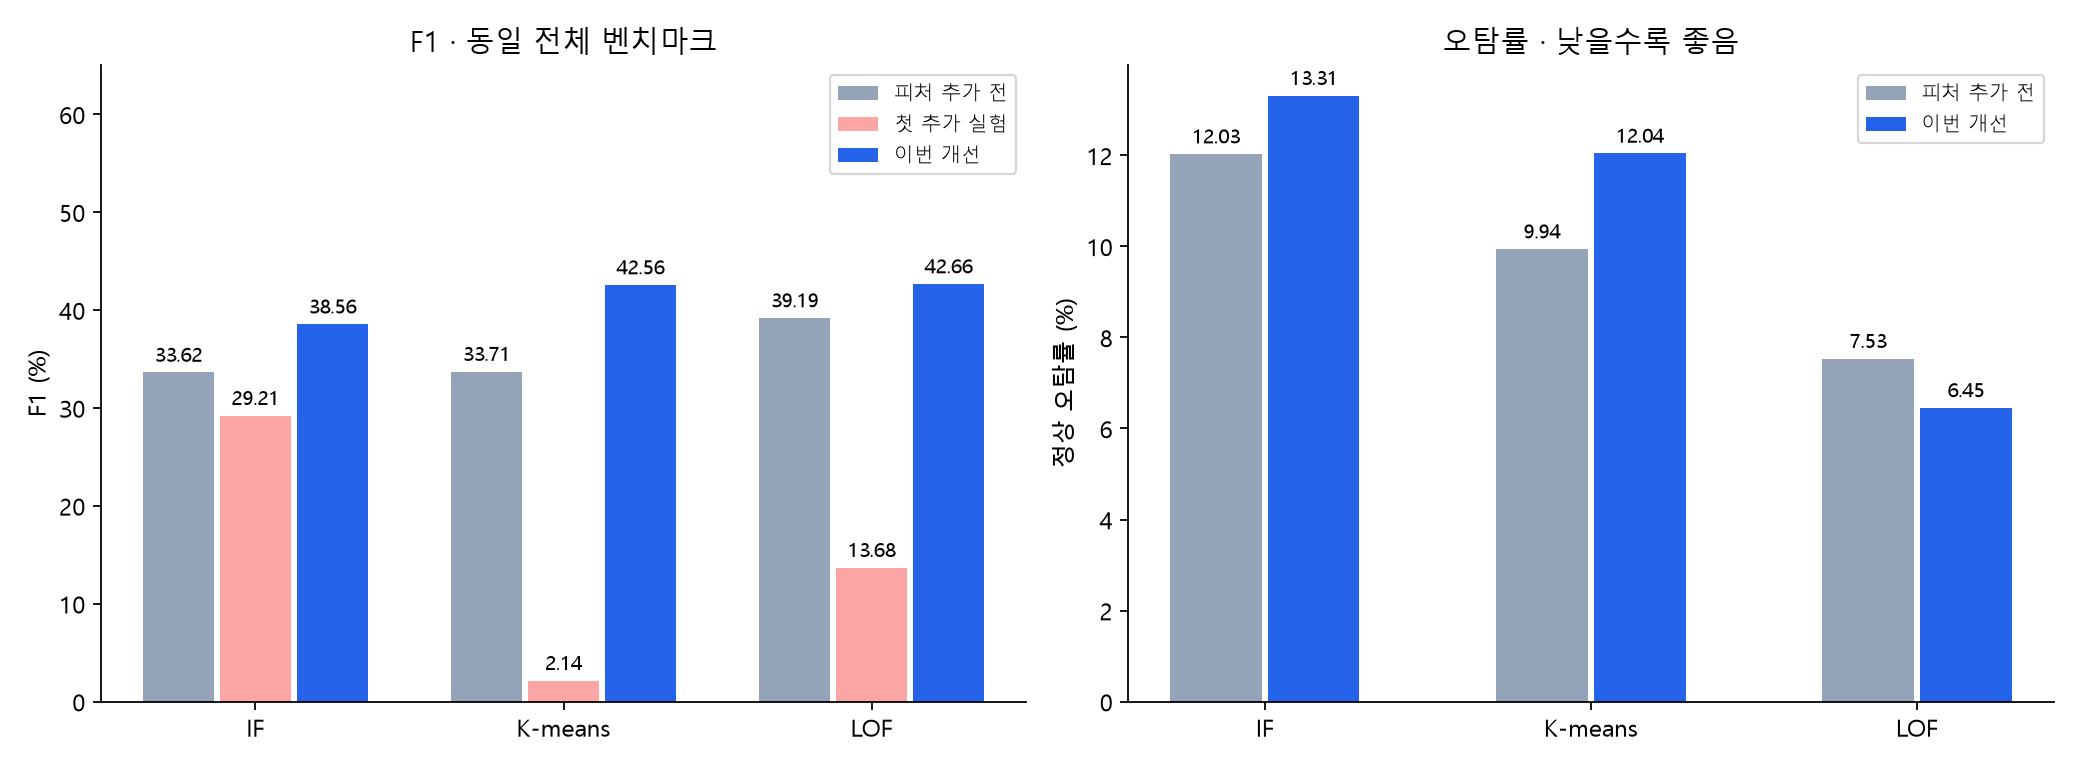

In [2]:
rows=[*old['pooled'],*[{**r,'method':r['method']+'_improved'} for r in result['pooled']]]
display(table(rows))
display(Image(filename=str(OUT/'figures/comparison.png')))

## 3. 무엇을 바꾸었나

- 불안정한 처리건수 자체 편차 피처 제외 후보(나머지 9개 유지)
- 안정적 스케일/압축과 알고리즘별 설정 비교
- IF는 기본 피처의 중복을 줄이는 view도 비교. Adapter 피처는 그대로 유지
- LOF hybrid는 기본 피처 스케일을 그대로 두고 Adapter 추가 블록만 안정화
- 모델과 경보선도 조정되었으므로 순수 피처 효과만의 비교는 아님

In [3]:
manifest=read(OUT/'handoff/manifest.json')
relevant={'if':['trees','samples','max_features'],'kmeans':['clusters','cluster_radius'],'lof':['neighbors','reference_cap','metric','deduplicate']}
for r in manifest['models']:
    a=r['algorithm']; settings=r['settings']
    values={k:settings.get(k,'full' if k=='view' else None) for k in ['transform','view','adapter_weight',*relevant[a]]}
    values.update({'normal_quantile':selected['selected'][a]['normal_quantile'],'threshold':r['threshold'],'total_features':len(r['columns']),'Adapter_features':r['adapter_feature_count'],'fit_or_reference_rows':r['fit_rows'],'detector_count':r['estimator_count']})
    display(Markdown('### '+a))
    display(pd.Series(values,name='값').to_frame())
display(Markdown('K-means 추가 고정값: batch_size=2048, n_init=10, max_iter=150. 군집별 정상 P95 거리로 정규화. 세 알고리즘의 seed=42.'))

### if

,값
transform,quantile
view,compact
adapter_weight,0.5
trees,300
samples,256
max_features,1.0
normal_quantile,0.96
threshold,0.565629
total_features,19
Adapter_features,9


### kmeans

,값
transform,quantile
view,full
adapter_weight,0.25
clusters,8
cluster_radius,True
normal_quantile,0.95
threshold,1.140096
total_features,37
Adapter_features,9
fit_or_reference_rows,19793


### lof

,값
transform,hybrid
view,full
adapter_weight,0.25
neighbors,75
reference_cap,4096
metric,euclidean
deduplicate,True
normal_quantile,0.97
threshold,2.693342
total_features,37


K-means 추가 고정값: batch_size=2048, n_init=10, max_iter=150. 군집별 정상 P95 거리로 정규화. 세 알고리즘의 seed=42.

## 4. 개발 탐색과 확인 데이터

설정은 search에서 선택하고 기존 confirmation에서 선택 후 확인. 이 분할들의 case_id는 상호 분리지만 반복 개선 중 이미 확인한 연구 집단이며 새로운 외부 블라인드 평가는 아니다. 최종 평가 결과가 구조 설계에 영향을 주었다는 사실도 메타데이터에 기록한다.

In [4]:
display(pd.DataFrame([{'algorithm':a,**r} for a,r in selected['baseline'].items()])[['algorithm','precision','recall','f1','normal_false_positive_rate']])
display(pd.DataFrame(read(OUT/'confirmation.json')['metrics'])[['algorithm','method','precision','recall','f1','normal_false_positive_rate']])

,algorithm,precision,recall,f1,normal_false_positive_rate
0,if,0.471118,0.305184,0.370417,0.066631
1,kmeans,0.430178,0.249571,0.315881,0.064294
2,lof,0.481520,0.315311,0.381081,0.066030


,algorithm,method,precision,recall,f1,normal_false_positive_rate
0,if,baseline,0.312428,0.400434,0.350999,0.168924
1,if,improved,0.349291,0.438281,0.388758,0.156511
2,kmeans,baseline,0.313689,0.369184,0.339182,0.154830
3,kmeans,improved,0.321116,0.470747,0.381794,0.190772
4,lof,baseline,0.433573,0.430035,0.431796,0.107691
5,lof,improved,0.478808,0.449132,0.463495,0.093714


## 5. 주요 5개와 시나리오별 결과

전체 표에는 컬럼 관계/Hard도 포함하며 아래 주요 5개 집계와 구분. 일괄 F1 상승이 모든 시나리오의 상승을 뜻하지 않는다.

,accuracy,precision,recall,f1,normal_false_positive_rate
method,,,,,
if,79.11,39.79,41.68,40.71,13.11
kmeans,81.78,46.85,43.57,45.15,10.28
lof,83.73,53.95,37.45,44.21,6.65


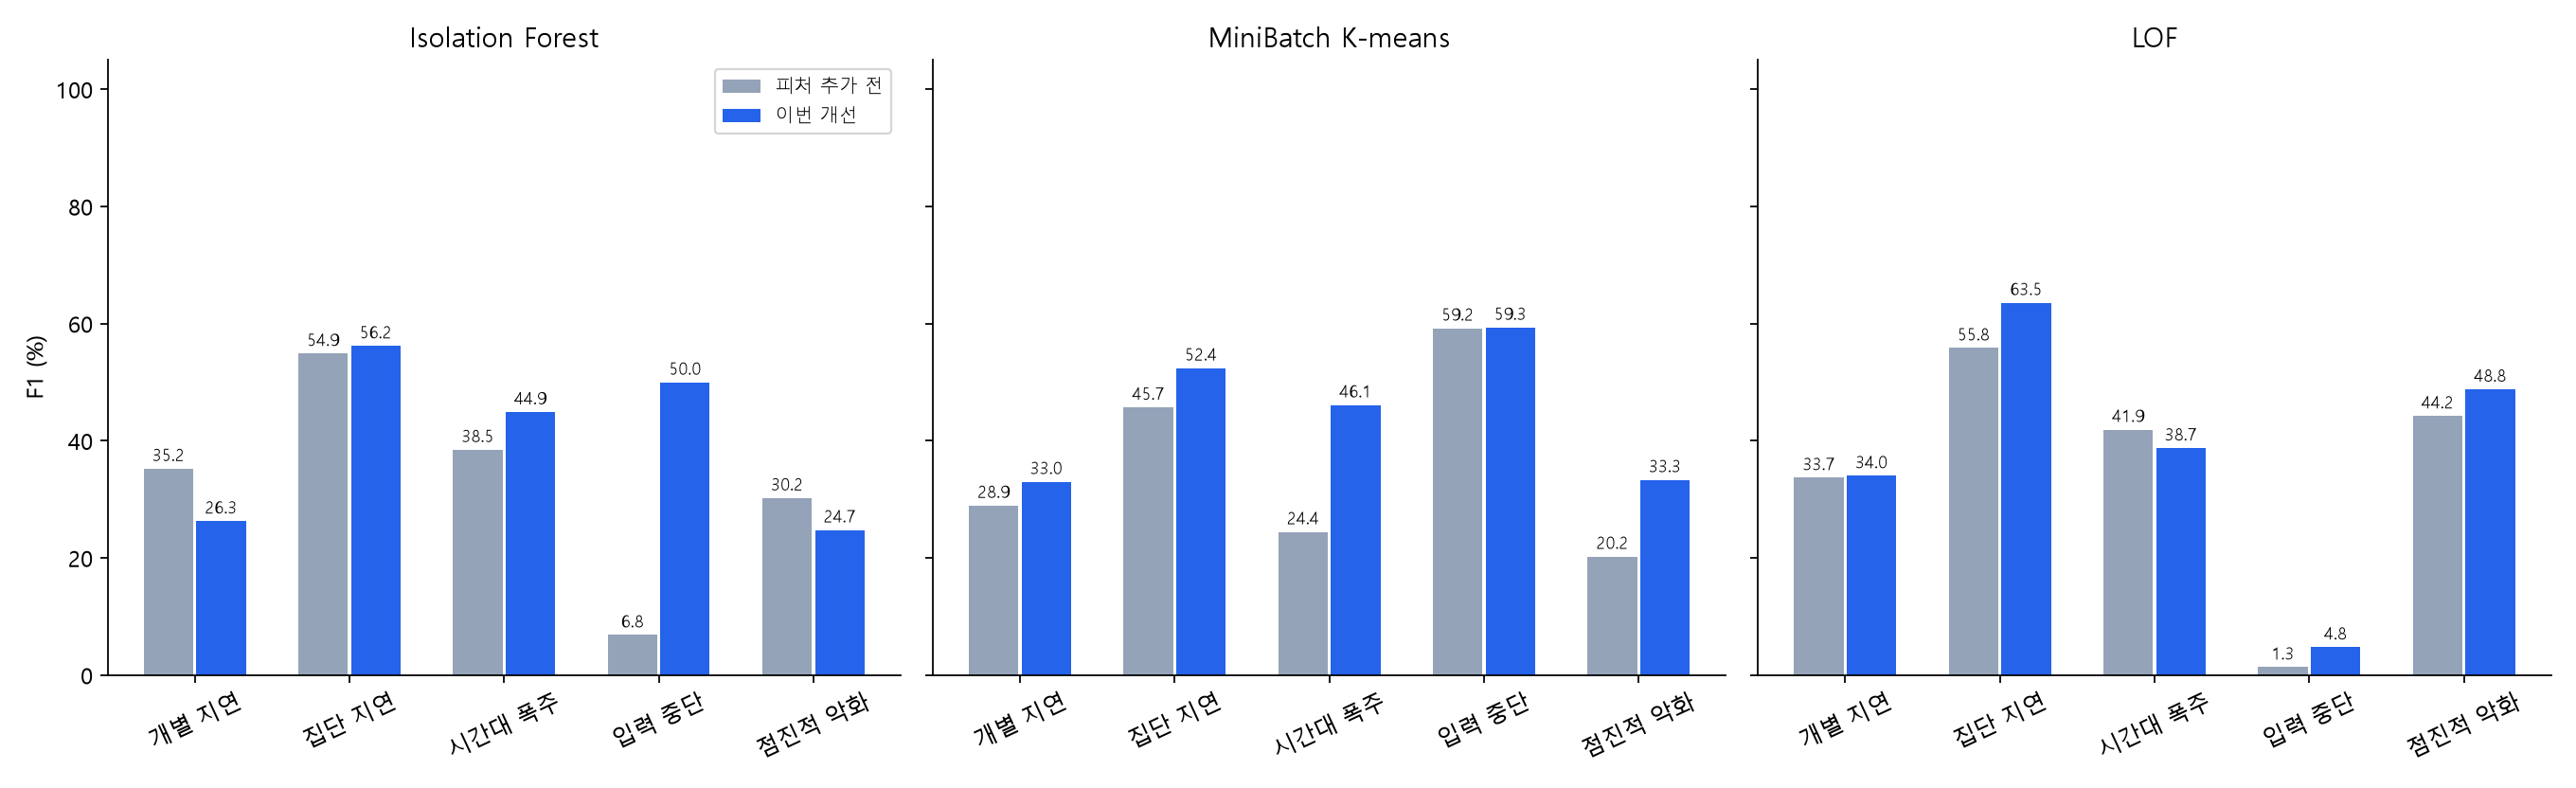

### individual_delay

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,63.22,15.83,77.15,26.26,38.07,14.37,70.71
kmeans,77.83,22.19,64.28,32.99,20.92,37.17,77.44
lof,84.16,26.31,48.05,34.00,12.48,22.83,77.82


### group_delay

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,79.77,41.80,85.53,56.16,21.26,65.90,89.04
kmeans,80.92,42.11,69.28,52.38,17.00,56.17,83.32
lof,86.19,52.94,79.46,63.54,12.61,76.61,88.20


### column_relation

...

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,85.69,56.37,44.85,49.96,6.57,56.36,87.51
kmeans,88.44,67.41,52.96,59.32,4.85,57.31,84.13
lof,83.89,40.34,2.52,4.75,0.71,36.74,80.59


### gradual_degradation

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,69.62,32.26,20.07,24.75,13.96,30.52,59.02
kmeans,72.74,42.58,27.37,33.32,12.23,34.98,62.93
lof,77.84,57.39,42.40,48.77,10.43,51.69,66.64


### mixed_hard

,accuracy,precision,recall,f1,normal_false_positive_rate,average_precision,roc_auc
method,,,,,,,
if,73.38,31.99,17.44,22.57,10.61,29.70,57.84
kmeans,60.97,24.67,36.75,29.52,32.10,23.33,53.51
lof,78.55,54.41,22.07,31.41,5.29,41.12,60.02


In [5]:
display(table(result['main_five_pooled']))
display(Image(filename=str(OUT/'figures/scenario_f1.png')))
for dataset in result['datasets']:
    display(Markdown('### '+dataset['dataset']))
    display(table(dataset['metrics']))

## 6. 분포와 실제 경보선

일반 막대 히스토그램. 각 정상/이상 집단 내 표본 비중. 점선보다 큰 점수가 경보. LOF는 긴 꼬리 때문에 표시 축만 log1p 변환하고 원점수 threshold를 범례에 표시. 판정/지표는 원점수 그대로 사용. 극단 꼬리는 표시 밖 비중 명시. 표본 그림과 전수 지표는 구분.

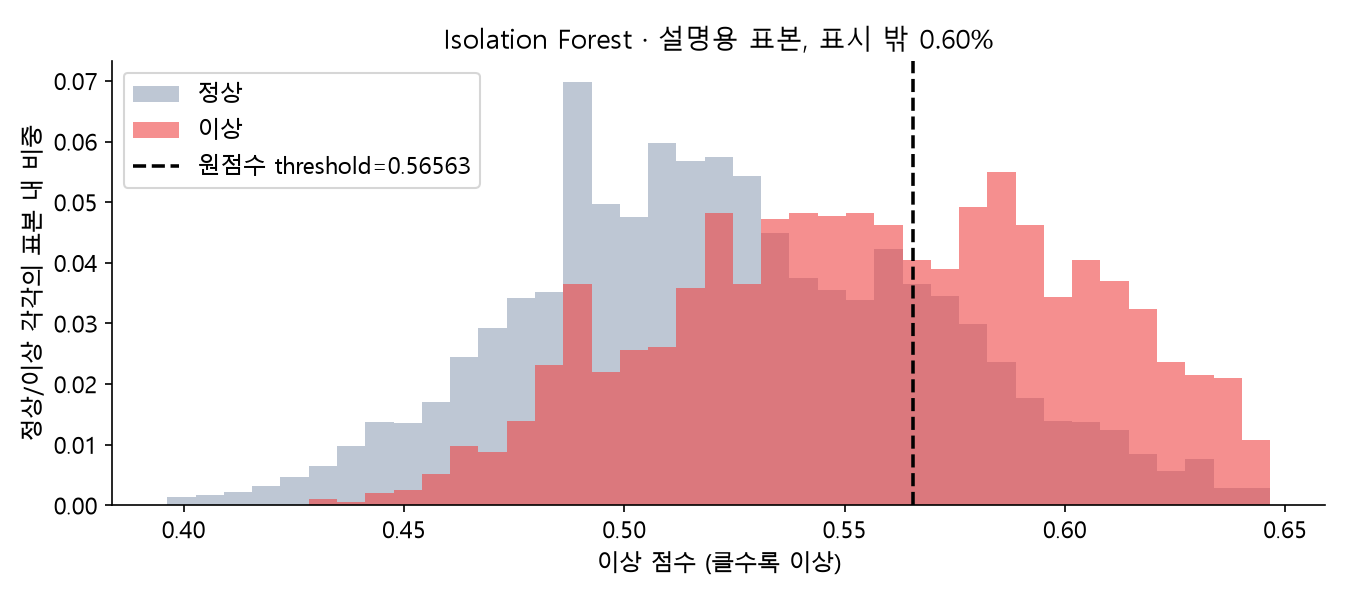

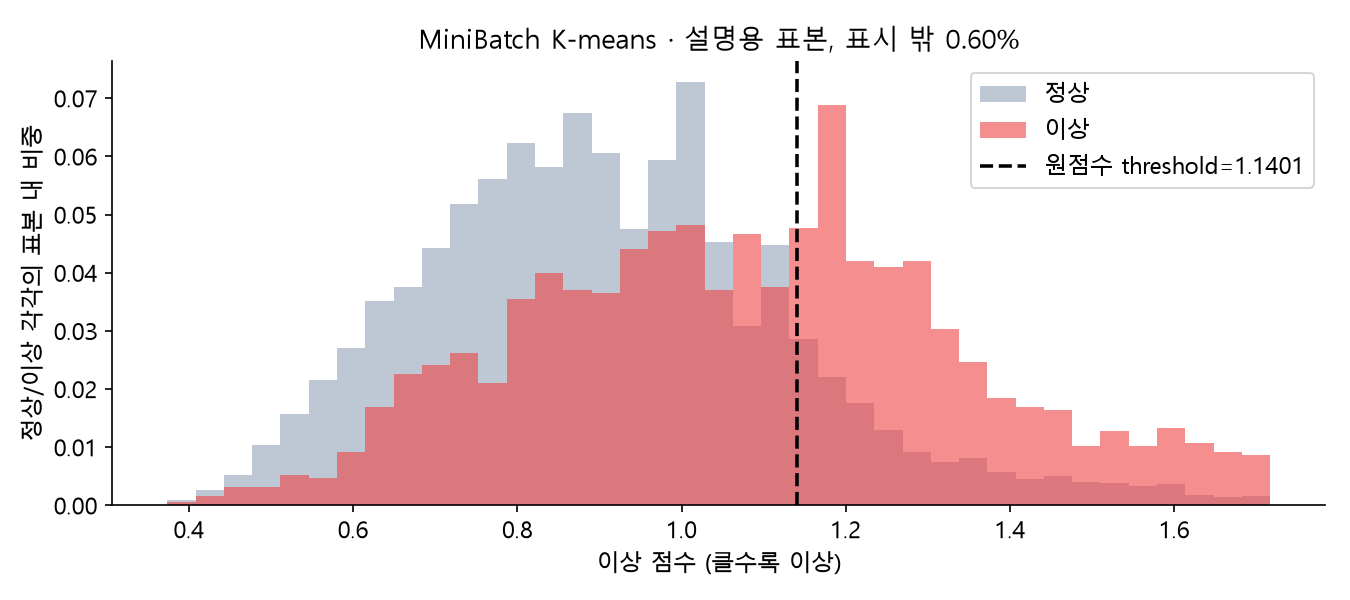

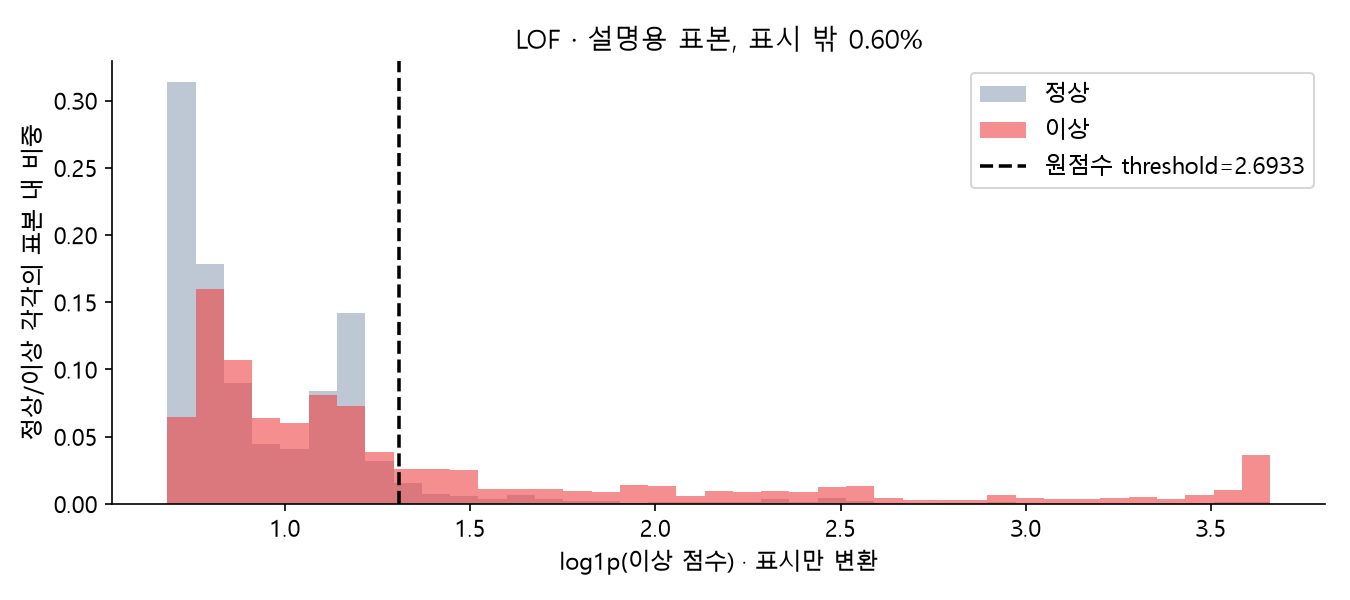

In [6]:
for a in ['if','kmeans','lof']:
    display(Image(filename=str(OUT/'figures'/f'{a}_scores.png')))

## 7. 유지한 Adapter 피처와 실제 사용

참고 통계는 정상 train 전용. 새 Adapter는 전체 참고 분포를 쓰며 별도 전문가 fallback은 없다. 참고 표본 수/단계는 진단용이고 탐지기 입력은 아니다.

In [7]:
manifest=read(OUT/'handoff/manifest.json')
for model in manifest['models']:
    display(Markdown('### '+model['algorithm']))
    display(pd.DataFrame({'Adapter 피처':[c for c in model['columns'] if c.startswith('adapter_')]}))

### if

,Adapter 피처
0,adapter_max_duration_z
1,adapter_p95_upper_tail
2,adapter_count_p95_z
3,adapter_count_p95_upper_tail
4,adapter_count_p95_lower_tail
5,adapter_stream_arrivals_z
6,adapter_reference_log_duration
7,adapter_delay_short_long
8,adapter_delay_ewma


### kmeans

,Adapter 피처
0,adapter_max_duration_z
1,adapter_p95_upper_tail
2,adapter_count_p95_z
3,adapter_count_p95_upper_tail
4,adapter_count_p95_lower_tail
5,adapter_stream_arrivals_z
6,adapter_reference_log_duration
7,adapter_delay_short_long
8,adapter_delay_ewma


### lof

,Adapter 피처
0,adapter_max_duration_z
1,adapter_p95_upper_tail
2,adapter_count_p95_z
3,adapter_count_p95_upper_tail
4,adapter_count_p95_lower_tail
5,adapter_stream_arrivals_z
6,adapter_reference_log_duration
7,adapter_delay_short_long
8,adapter_delay_ewma


## 8. 개선 폭의 표본 불확실성

300회 시나리오별 사례 단위 쌍체 부트스트랩. 정상/이상 재생 쌍을 함께 표집. 같은 원본 pool·생성기를 공유하므로 실제 운영 일반화 신뢰구간이 아님.

In [8]:
display(pd.DataFrame(read(OUT/'paired_bootstrap.json')['records']))

,algorithm,f1_delta_ci95_percentage_points
0,if,"[4.620825828046691, 5.291065023000327]"
1,kmeans,"[8.482643410999966, 9.24441391596598]"
2,lof,"[3.373785721885464, 3.590979018681548]"


## 9. 적용 범위

- 정상 S 후보와 합성 prior에 기반, 실제 장애 전반의 성능 보장 아님.
- 하이퍼파라미터 선택에는 개발 정답을 사용. 완전 무라벨 연구가 아님.
- 실제 Adapter 전체 동시 Process 트래픽 피처는 이번 독립 재생에 없으므로 주장하지 않음.
- 운영 모델 자동 교체·GitHub 업로드·Notion 수정 없음.
- 모델은 연속 1분 grid와 완료 로그의 과거 문맥이 필요하며, backend 워커의 상태 관리가 별도로 필요.